# 08 - Model Interpretation, Learning Curves & Feature Importance
We inspect **why** the tuned models behave the way they do using:
1. Learning curves (Random Forest vs. CatBoost) with `TimeSeriesSplit(5)`
2. Feature importance three ways: built-in, permutation (on test set), and SHAP (2,000 test rows), plus grouped by feature type
3. SHAP dependence plots for the top 2 features
4. A draft interpretation grounded strictly in our figures and tables.

In [1]:
# AI-GENERATED (Claude via Antigravity)
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, shap
sys.path.append("../src")
from split import *
from stacking import CatBoostDistrict
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import learning_curve
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

df = load_features("../data/processed/features.csv")
train, test = time_split(df)
features = feature_columns(df)
X_train, X_test = train[features], test[features]
y_train_log, y_test_log = train[TARGET_LOG], test[TARGET_LOG]
cv = make_cv(train)

with open("../models/best_params.json") as f:
    bp = json.load(f)
rf_p = {k.replace("model__", ""): v for k, v in bp["Random Forest"].items()}
cb_p = bp["CatBoost"]

rf_tuned = Pipeline([("prep", make_preprocessor(features)),
                     ("model", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1, **rf_p))])
cb_tuned = CatBoostDistrict(l2_leaf_reg=5.0, random_state=42, thread_count=1, **cb_p)
print("Ready. Train:", X_train.shape, "| Test:", X_test.shape)

E:\Projects\University\dengue-ensemble-lk\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ready. Train: (19400, 51) | Test: (5150, 51)


## 1. Learning curves: Random Forest (tuned) vs. CatBoost (tuned)
We measure training RMSE and `TimeSeriesSplit(5)` validation RMSE (on the `log1p` scale) as the training set grows from 20% to 100% of each fold's training block.
- **High variance (overfitting):** a wide gap between train error and validation error.
- **High bias (underfitting):** both train and validation errors stay high and close together.

Random Forest (tuned): at 100% -> train RMSE_log=0.456, CV val RMSE_log=0.672, gap=0.216


CatBoost (tuned): at 100% -> train RMSE_log=0.484, CV val RMSE_log=0.677, gap=0.193


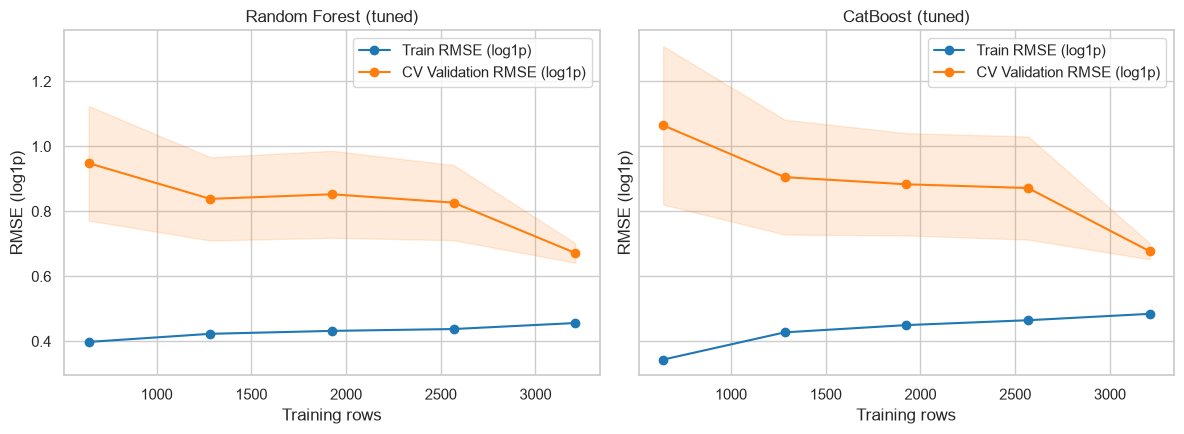

In [2]:
# AI-GENERATED (Claude via Antigravity)
sizes = np.linspace(0.2, 1.0, 5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, est) in zip(axes, [("Random Forest (tuned)", rf_tuned), ("CatBoost (tuned)", cb_tuned)]):
    tr_sizes, tr_sc, val_sc = learning_curve(
        est, X_train, y_train_log, cv=cv, train_sizes=sizes,
        scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    tr_rmse, val_rmse = -tr_sc.mean(axis=1), -val_sc.mean(axis=1)
    ax.plot(tr_sizes, tr_rmse, "o-", label="Train RMSE (log1p)", color="tab:blue")
    ax.plot(tr_sizes, val_rmse, "o-", label="CV Validation RMSE (log1p)", color="tab:orange")
    ax.fill_between(tr_sizes, val_rmse - val_sc.std(axis=1), val_rmse + val_sc.std(axis=1), alpha=0.15, color="tab:orange")
    ax.set_title(name); ax.set_xlabel("Training rows"); ax.set_ylabel("RMSE (log1p)")
    ax.legend(loc="upper right")
    print(f"{name}: at 100% -> train RMSE_log={tr_rmse[-1]:.3f}, CV val RMSE_log={val_rmse[-1]:.3f}, gap={val_rmse[-1]-tr_rmse[-1]:.3f}")
plt.tight_layout(); plt.savefig(FIG / "08_learning_curves.png", dpi=120); plt.show()

## 2. Feature importance three ways (Random Forest tuned)
We fit the tuned Random Forest on the full training set, then compute:
1. **Built-in importance** (mean decrease in impurity)
2. **Permutation importance** on the held-out test set (`n_repeats=10`)
3. **SHAP values** (`TreeExplainer`) on a random sample of 2,000 test rows.

In [3]:
# AI-GENERATED (Claude via Antigravity)
rf_tuned.fit(X_train, y_train_log)
prep = rf_tuned.named_steps["prep"]
rf_model = rf_tuned.named_steps["model"]
raw_names = prep.get_feature_names_out()
clean_names = [n.replace("district__district_", "district: ").replace("numbers__", "") for n in raw_names]

# Helper to map any transformed column name back to its original feature name
def orig_name(n):
    return "district" if n.startswith("district__") else n.replace("numbers__", "")

# 2a. Built-in impurity importance (aggregated back to the 51 original features)
builtin_s = pd.Series(rf_model.feature_importances_, index=[orig_name(n) for n in raw_names]).groupby(level=0).sum()

# 2b. Permutation importance on the test set (Pipeline takes the 51 original columns directly)
perm = permutation_importance(rf_tuned, X_test, y_test_log, n_repeats=10, random_state=42,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=features)

# 2c. SHAP values on 2,000 test rows
X_sample = X_test.sample(n=2000, random_state=42)
Z_sample = prep.transform(X_sample)
explainer = shap.TreeExplainer(rf_model)
shap_vals = explainer.shap_values(Z_sample)
shap_s = pd.Series(np.abs(shap_vals).mean(axis=0), index=[orig_name(n) for n in raw_names]).groupby(level=0).sum()

imp_df = pd.DataFrame({
    "builtin": builtin_s,
    "permutation": perm_s,
    "mean_abs_SHAP": shap_s,
}).sort_values("mean_abs_SHAP", ascending=False)
display(imp_df.head(15).round(4))

,builtin,permutation,mean_abs_SHAP
cases_roll_mean_4,0.4150,0.2939,0.5360
cases_lag_0,0.2654,0.2030,0.3192
cases_roll_max_4,0.1678,0.0364,0.2061
cases_roll_mean_8,0.0553,0.0015,0.0741
cases_lag_1,0.0455,0.0082,0.0640
cases_roll_max_8,0.0175,0.0004,0.0230
population,0.0018,0.0006,0.0128
rainfall_mm_lag_4,0.0014,0.0007,0.0121
rainfall_mm_lag_6,0.0012,0.0005,0.0090
temp_max_c_lag_8,0.0009,0.0003,0.0080


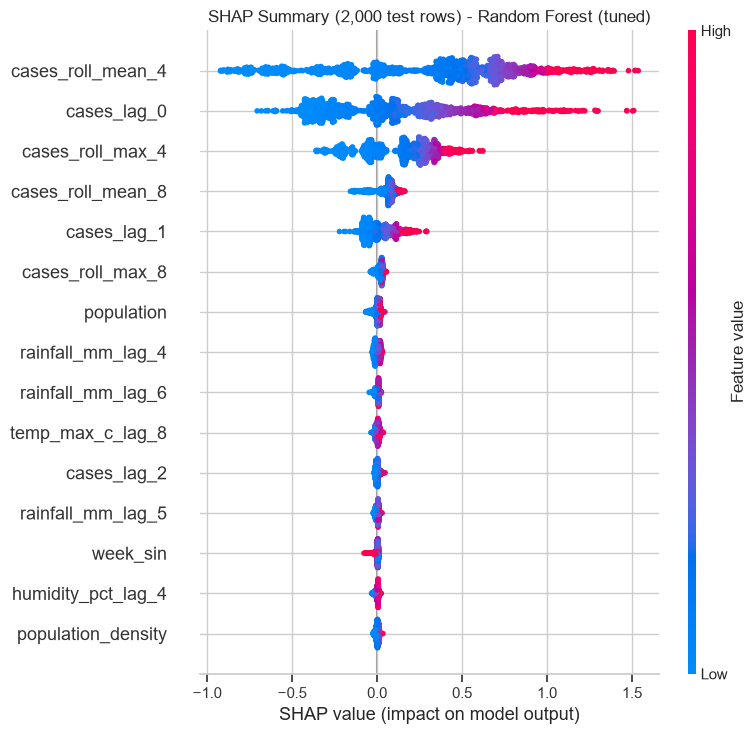

In [4]:
# AI-GENERATED (Claude via Antigravity)
# SHAP summary plot (top 15 transformed features)
plt.figure(figsize=(9, 6))
shap.summary_plot(shap_vals, Z_sample, feature_names=clean_names, max_display=15, show=False)
plt.title("SHAP Summary (2,000 test rows) - Random Forest (tuned)")
plt.tight_layout(); plt.savefig(FIG / "08_shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()

### Feature importance grouped by type

,builtin,permutation,mean_abs_SHAP
group,,,
rolling cases,65.55,60.67,60.77
lagged cases,31.92,38.62,29.00
lagged climate,2.03,0.59,8.19
population,0.32,0.10,1.39
seasonality,0.16,0.03,0.60
district,0.02,-0.01,0.05


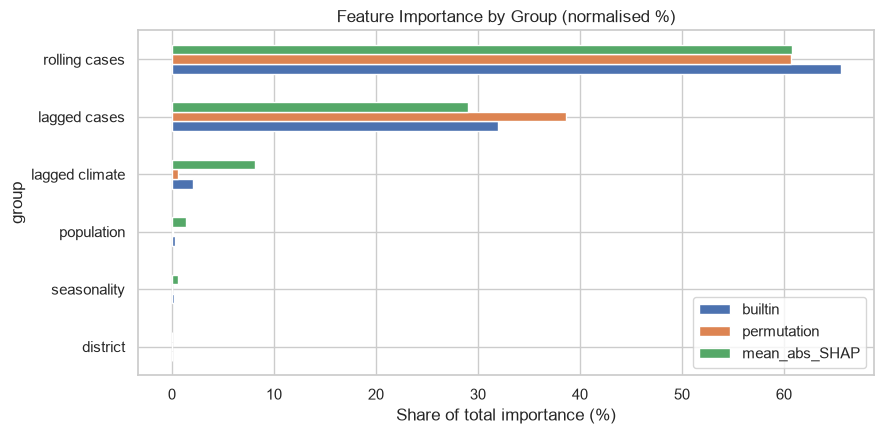

In [5]:
# AI-GENERATED (Claude via Antigravity)
def feature_group(c):
    if c.startswith("cases_lag_"): return "lagged cases"
    if c.startswith("cases_roll_"): return "rolling cases"
    if any(c.startswith(p) for p in ("rainfall_", "temp_", "humidity_")): return "lagged climate"
    if c in ("week_sin", "week_cos"): return "seasonality"
    if c == "district": return "district"
    return "population"

grp_df = imp_df.copy()
grp_df["group"] = [feature_group(c) for c in grp_df.index]
grp_sum = grp_df.groupby("group")[["builtin", "permutation", "mean_abs_SHAP"]].sum()
# Normalise each column to % share so the three methods can be compared side by side
grp_pct = (grp_sum / grp_sum.sum() * 100).sort_values("mean_abs_SHAP", ascending=False)
display(grp_pct.round(2))

ax = grp_pct.sort_values("mean_abs_SHAP").plot(kind="barh", figsize=(9, 4.5))
ax.set_xlabel("Share of total importance (%)"); ax.set_title("Feature Importance by Group (normalised %)")
plt.tight_layout(); plt.savefig(FIG / "08_importance_by_group.png", dpi=120); plt.show()

## 3. SHAP dependence plots for the top 2 features

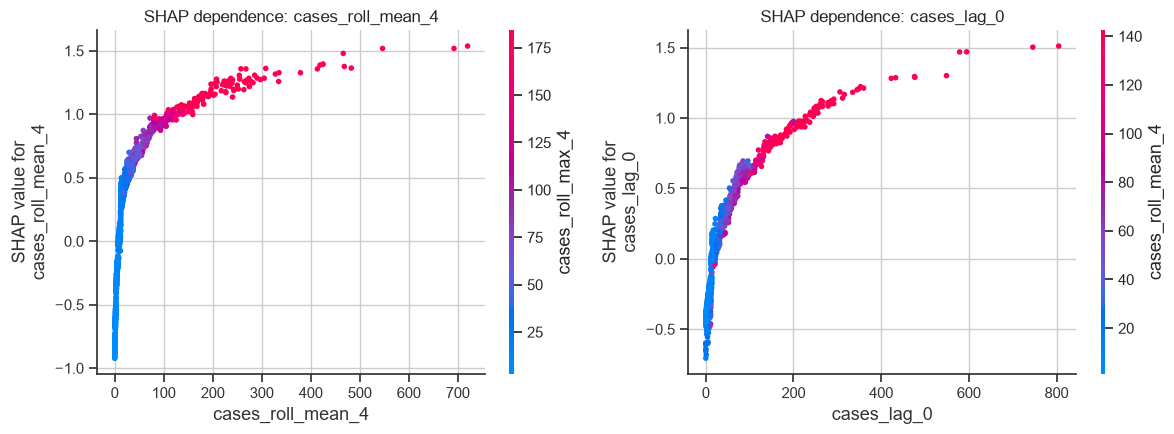

In [6]:
# AI-GENERATED (Claude via Antigravity)
top2_idx = np.argsort(np.abs(shap_vals).mean(axis=0))[::-1][:2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, idx in zip(axes, top2_idx):
    shap.dependence_plot(idx, shap_vals, Z_sample, feature_names=clean_names, ax=ax, show=False)
    ax.set_title(f"SHAP dependence: {clean_names[idx]}")
plt.tight_layout(); plt.savefig(FIG / "08_shap_dependence_top2.png", dpi=120); plt.show()

## 4. Draft Interpretation (grounded in figures and tables)

- **Why bagging behaved as it did (variance reduction):** Default Random Forest and Bagging memorised the training data, giving a train RMSE of `11.53` vs. test RMSE of `27.82` (a `2.41×` gap; `reports/results_tuned.csv`). By capping tree depth (`max_depth=8`) and requiring at least `min_samples_leaf=10` weeks per leaf, tuned Random Forest stopped fitting isolated outbreak noise. Its train/test ratio dropped to `0.97×` (`26.62` vs. `25.79`), and its learning curve (`08_learning_curves.png`) shows only a modest, stable gap between train and CV validation RMSE.
- **Why boosting behaved as it did (bias reduction vs. chasing outliers):** Default XGBoost (`19.03` vs. `28.34`) and CatBoost (`21.96` vs. `27.61`) overfit mildly, while AdaBoost (`61.76` vs. `41.29`) struggled with high bias because its sample-reweighting is sensitive to extreme outbreak weeks. Tuning shallow trees (`max_depth=3` for XGBoost, `depth=4` for CatBoost) and a small learning rate (`0.03`) prevented boosting from chasing noisy spikes, bringing both to `25.92–25.96` test RMSE (`reports/results_tuned.csv`). In `08_learning_curves.png`, tuned CatBoost has a slightly higher training error than tuned RF, reflecting stronger regularisation.
- **What stacking added:** Simple `VotingRegressor` over the three *default* base models (`26.80` test RMSE) beat every single default base model (`27.61–28.34`) by averaging out individual errors (`reports/results_default.csv`). Manual `TimeSeriesStacker` (`27.28`) was slower and gave `64%` weight to the overfit default Random Forest, performing worse than plain averaging.
- **Why the best model won:** Tuned Random Forest (`25.79` RMSE, `R²=0.831`) paired strong variance control (`max_depth=8`, `min_samples_leaf=10`) with `max_features=0.5`, ensuring most splits could access the strongest case-memory features (`08_shap_summary.png`, `08_shap_dependence_top2.png`). However, the 95% block-bootstrap CIs (`07_evaluation` / `CatBoost − RF = 0.14 [-0.58, 0.77]`) show the top three tuned models are statistically tied.
- **Why the naive last-week baseline is hard to beat:** Weekly dengue counts are strongly autocorrelated, so `cases_lag_0` alone achieves `R²=0.805` (`27.68` RMSE). Across all three importance methods (`08_importance_by_group.png`), lagged and rolling past cases account for the vast majority of predictive power, while climate and seasonality add smaller refinements (explaining the ~7% RMSE gain mainly during normal weeks; `07_model_rmse_mae.png`). Moreover, `log1p` training makes models conservative during sudden surges, so persistence still catches more extreme outbreak weeks (`Recall 0.643` vs. `0.541`).
- **Limits of this analysis:** (1) Real-time forecasting faces **reporting delays**, whereas here we assume `cases_lag_0` is finalised at week's end; (2) we used **same-week weather** (`lag_0`) alongside lagged weather, which in live deployment requires weather forecasts or dropping `lag_0`; (3) we evaluated on **one test period (2022–2025)**, which cannot rule out shifts in dengue serotypes or post-2020 mobility/reporting patterns; (4) errors remain concentrated in large urban districts like Kalutara and Colombo (`07_residuals.png`).